# DAZONE 2026 — Random Search duy nhất UPLIFT_RF_CIT theo QINI

Notebook này được chỉnh từ file gốc train **INT_RF** và **UPLIFT_RF_CIT**.

Bản này chỉ tập trung vào **1 model duy nhất**:

- **UPLIFT_RF_CIT**: CausalML Uplift Random Forest với `evaluationFunction="CIT"`.

Chỉ số chọn model:

```python
QINI = qini_cash + qini_card
```

Điểm chính đã thêm:

- Random search tổ hợp tham số cho **UPLIFT_RF_CIT**.
- Đánh giá bằng **5-fold cross-validation** cho cả `cash_sign_30d` và `card_sign_30d`.
- Mỗi configuration đều in Qini cash/card/total ra Kaggle Logs.
- Configuration tốt nhất được in rõ ở Logs dưới biến **A** để copy và tái tạo lại model.
- Output lưu thêm:
  - `uplift_rf_cit_random_search_results.csv`
  - `uplift_rf_cit_best_config_A.json`
  - `fold_qini_logs.csv`
  - `final_scores_train.csv`


In [1]:
# ============================================================
# 0. MINIMAL ENVIRONMENT SETUP
# ============================================================
# Bản này chỉ chạy UPLIFT_RF_CIT nên causalml là bắt buộc.
# Nếu Kaggle environment chưa có causalml, cell này sẽ thử cài.
# Nếu Kaggle không cho Internet, hãy bật Internet hoặc cài causalml trước khi chạy notebook.

RUN_INSTALL_CAUSALML = True

import importlib.util
import subprocess
import sys


def is_installed(import_name: str) -> bool:
    return importlib.util.find_spec(import_name) is not None


if RUN_INSTALL_CAUSALML and not is_installed("causalml"):
    print("causalml not found -> installing causalml ...", flush=True)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "causalml"])
        print("OK: causalml installed", flush=True)
    except Exception as e:
        print("WARNING: causalml install failed:", repr(e), flush=True)
        print("Notebook sẽ dừng ở bước import causalml nếu package chưa có.", flush=True)
elif RUN_INSTALL_CAUSALML:
    print("OK: causalml already installed", flush=True)
else:
    print("RUN_INSTALL_CAUSALML=False -> skip install", flush=True)


causalml not found -> installing causalml ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 3.6 MB/s eta 0:00:00
OK: causalml installed


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import time
import json
import random
import pprint
import warnings
from pathlib import Path

# Giới hạn thread để ổn định runtime trên Kaggle/CPU.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
N_JOBS = 4

# ============================================================
# UPLIFT_RF_CIT RANDOM SEARCH CONFIG
# ============================================================
# RANDOM_SEARCH_N_ITER = số configuration UPLIFT_RF_CIT sẽ thử.
# Có thể tăng lên 50 hoặc 100 nếu Kaggle runtime đủ dài.
RANDOM_SEARCH_N_ITER = 30

# Luôn thử baseline config đầu tiên, sau đó random thêm các config còn lại.
UPLIFT_RF_BASELINE_CONFIG = {
    "n_estimators": 80,
    "max_depth": 5,
    "min_samples_leaf": 120,
    "min_samples_treatment": 40,
    "max_features_cap": 12,
}

# Không gian random search.
# Giữ list value trên một dòng ngang để dễ chỉnh.
UPLIFT_RF_RANDOM_SEARCH_SPACE = {
    "n_estimators": [60, 80, 120, 160, 220],
    "max_depth": [3, 4, 5, 6, 8, None],
    "min_samples_leaf": [50, 80, 100, 120, 160, 220],
    "min_samples_treatment": [20, 30, 40, 60, 80, 120],
    "max_features_cap": [6, 8, 10, 12, 16, 20, 32],
}

CAUSALML_CRITERION = "CIT"
SELECTED_MODEL_NAMES = ["UPLIFT_RF_CIT"]

try:
    from causalml.inference.tree import UpliftRandomForestClassifier
    HAS_CAUSALML = True
    print("causalml: available", flush=True)
except Exception as e:
    HAS_CAUSALML = False
    print("causalml unavailable -> UPLIFT_RF_CIT cannot run:", repr(e), flush=True)

print("=" * 100, flush=True)
print("UPLIFT_RF_CIT random search setup", flush=True)
print(f"RANDOM_SEARCH_N_ITER = {RANDOM_SEARCH_N_ITER}", flush=True)
print("UPLIFT_RF_BASELINE_CONFIG =", UPLIFT_RF_BASELINE_CONFIG, flush=True)
print("UPLIFT_RF_RANDOM_SEARCH_SPACE =", UPLIFT_RF_RANDOM_SEARCH_SPACE, flush=True)
print("=" * 100, flush=True)


Failed to import duecredit due to No module named 'duecredit'


causalml: available
UPLIFT_RF_CIT random search setup
RANDOM_SEARCH_N_ITER = 30
UPLIFT_RF_BASELINE_CONFIG = {'n_estimators': 80, 'max_depth': 5, 'min_samples_leaf': 120, 'min_samples_treatment': 40, 'max_features_cap': 12}
UPLIFT_RF_RANDOM_SEARCH_SPACE = {'n_estimators': [60, 80, 120, 160, 220], 'max_depth': [3, 4, 5, 6, 8, None], 'min_samples_leaf': [50, 80, 100, 120, 160, 220], 'min_samples_treatment': [20, 30, 40, 60, 80, 120], 'max_features_cap': [6, 8, 10, 12, 16, 20, 32]}


## 2. Load dữ liệu + feature dropping


In [3]:
# ============================================================
# 2. LOAD DATA + FEATURE DROPPING CONFIG
# ============================================================

FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# Tùy chỉnh feature dropping:
#   None -> baseline, không drop feature nào.
#   int  -> drop 1 feature theo ID. Ví dụ: COL_IDX = 0.
#   list/tuple/set/range -> drop nhiều feature. Ví dụ: COL_IDX = [2, 3, 4, 5].
#   list(range(a, b)) -> drop liên tiếp ID a..b-1. Ví dụ: list(range(2, 6)) = 2,3,4,5.
#   string "a:b" -> drop liên tiếp ID a..b-1. Ví dụ: "2:6" = 2,3,4,5.
#   string/list tên feature -> drop trực tiếp theo tên feature gốc. Ví dụ: ["cli_age", "risk_grp"].
#
# Ví dụ chạy:
#   COL_IDX = None
#   COL_IDX = 0
#   COL_IDX = [2, 3]
#   COL_IDX = list(range(2, 6))
#   COL_IDX = "2:6"
COL_IDX = None

feat_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
tgt_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"

TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]




def normalize_feature_drop_selection(selection):
    """Chuẩn hóa cấu hình drop feature.

    Trả về:
    - drop_ids: list ID trong FEATURE_DROP_PRIORITY_LIST.
    - drop_base_cols: list tên feature gốc cần drop.

    Hỗ trợ:
    - None
    - int
    - list/tuple/set/range chứa int hoặc tên feature
    - string "a:b" để drop ID a..b-1
    - string tên feature gốc
    """
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                start, stop = int(m.group(1)), int(m.group(2))
                return list(range(start, stop))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError(
            "COL_IDX chỉ hỗ trợ None, int, range, slice, str, "
            "hoặc list/tuple/set chứa int/tên feature."
        )

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        elif isinstance(item, str):
            base_col = item.strip()
            if base_col not in FEATURE_DROP_PRIORITY_LIST:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong df_feature.")
                idx = None
            else:
                idx = FEATURE_DROP_PRIORITY_LIST.index(base_col)
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        else:
            raise TypeError(f"COL_IDX chứa phần tử không hợp lệ: {item!r}")

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    """Match cột gốc và các cột one-hot/encoded sinh ra từ feature gốc."""
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df):
    """Return W: 1 = Cash strategy, 0 = Card strategy."""
    if TREAT_COL_BINARY in feature_df.columns:
        return feature_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY
    if TREAT_COL_RAW not in feature_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong df_feature.csv")

    s = feature_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int).to_numpy(), TREAT_COL_RAW

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")
    return mapped.astype(int), TREAT_COL_RAW




feat = pd.read_csv(feat_path)
tgt = pd.read_csv(tgt_path)

W, TREAT_COL = encode_treatment_cash(feat)
Y_cash = tgt[TARGET_CASH].astype(int).to_numpy()
Y_card = tgt[TARGET_CARD].astype(int).to_numpy()

ID_COL = next((col for col in ID_CANDIDATES if col in feat.columns), None)
FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS = normalize_feature_drop_selection(COL_IDX)
FEATURE_DROP_BASE_COL = None if len(FEATURE_DROP_BASE_COLS) == 0 else "|".join(FEATURE_DROP_BASE_COLS)
FEATURE_DROP_COL_IDX = None if len(FEATURE_DROP_IDXS) == 0 else "|".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)

drop_cols_in_feat = []
for base_col in FEATURE_DROP_BASE_COLS:
    drop_cols_in_feat.extend(match_base_feature_columns(feat.columns, base_col))
# Deduplicate while preserving order.
drop_cols_in_feat = list(dict.fromkeys(drop_cols_in_feat))

index_like_cols = [c for c in feat.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
exclude_cols = set(drop_cols_in_feat + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
if ID_COL is not None:
    exclude_cols.add(ID_COL)

FEAT_COLS = [col for col in feat.columns if col not in exclude_cols]
X_df = feat[FEAT_COLS].copy()
X = X_df.to_numpy(dtype=np.float32)

w_cash = (W == 1).astype(int)
w_card = (W == 0).astype(int)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped df_feature columns ({len(drop_cols_in_feat)}): {drop_cols_in_feat}")
print("=" * 80)

print(f"N={len(X):,} | features={X.shape[1]}")
print(f"Treatment Cash: {W.sum():,} ({W.mean():.2%}) | Card: {(1-W).sum():,} ({(1-W).mean():.2%})")
print(f"Cash target rate: {Y_cash.mean():.4%} | Card target rate: {Y_card.mean():.4%}")
print("Feature NaN total:", int(pd.isna(X_df).sum().sum()))


FEATURE DROPPING: baseline, không drop feature nào
N=136,992 | features=62
Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Cash target rate: 5.9186% | Card target rate: 2.7111%
Feature NaN total: 0


In [4]:
# ============================================================
# 3. OPTIONAL TEST FEATURE LOADING
# ============================================================
# Notebook chỉ dùng test file đã clean/one-hot tương thích với df_feature.csv.
# Nếu không có test feature đã clean, phần submission sẽ tự skip.


def find_optional_test_feature():
    names = ["df_feature_test.csv", "test_feature.csv", "X_test.csv", "test.csv"]
    roots = [p for p in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
             if p.exists() and str(p.resolve()) not in ["/", "/mnt"]]
    for root in roots:
        for name in names:
            direct = root / name
            if direct.exists():
                return direct
            try:
                hits = list(root.rglob(name))
                if hits:
                    return sorted(hits, key=lambda p: len(str(p)))[0]
            except Exception:
                pass
    return None


def build_test_matrix(test_feature_path):
    test_feat = pd.read_csv(test_feature_path)
    test_id_col = next((col for col in ID_CANDIDATES if col in test_feat.columns), None)
    test_id = make_id_series(test_feat, id_col=test_id_col)

    # Align đúng FEAT_COLS của train: thiếu cột thì fill 0, thừa cột thì bỏ.
    X_test_df = test_feat.reindex(columns=FEAT_COLS, fill_value=0).copy()
    return test_feat, test_id, X_test_df, X_test_df.to_numpy(dtype=np.float32)


test_path = find_optional_test_feature()
if test_path is None:
    test_feat = None
    test_id = None
    X_test_df = None
    X_test = None
    print("Không tìm thấy test feature đã clean -> skip submission.")
else:
    test_feat, test_id, X_test_df, X_test = build_test_matrix(test_path)
    print("Test feature path:", test_path)
    print(f"X_test shape={X_test.shape}")


Không tìm thấy test feature đã clean -> skip submission.


In [5]:
# ============================================================
# 4. LEAKAGE AUDIT
# ============================================================
FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if ID_COL is not None:
    FORBIDDEN_FEATURE_COLS.add(ID_COL)

forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

assert TARGET_CASH not in FEAT_COLS and TARGET_CARD not in FEAT_COLS, "DATA LEAKAGE: target bị đưa vào X"
assert TREAT_COL_BINARY not in FEAT_COLS and TREAT_COL_RAW not in FEAT_COLS, "DATA LEAKAGE: treatment bị đưa vào X"
if ID_COL is not None:
    assert ID_COL not in FEAT_COLS, "DATA LEAKAGE/RISK: ID bị đưa vào X"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(feat.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(feat.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})

print("Leakage audit: PASSED")
display(feature_drop_audit)


Leakage audit: PASSED


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


## 3. Qini metric + fold cố định


In [6]:
# ============================================================
# 5. QINI METRIC + FIXED FOLDS
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def make_fold_id(w_event, y):
    key = (np.asarray(w_event, dtype=int) * 2 + np.asarray(y, dtype=int)).astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.zeros(len(y), dtype=int)
    dummy_x = np.zeros(len(y))
    for fold, (_, va) in enumerate(skf.split(dummy_x, key), 1):
        fold_id[va] = fold
    return fold_id


fold_ids = {
    "cash": make_fold_id(w_cash, Y_cash),
    "card": make_fold_id(w_card, Y_card),
}

print("Fold distribution cash target:", pd.Series(fold_ids["cash"]).value_counts().sort_index().to_dict())
print("Fold distribution card target:", pd.Series(fold_ids["card"]).value_counts().sort_index().to_dict())


Fold distribution cash target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}
Fold distribution card target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}


## 4. Model helpers: UPLIFT_RF_CIT only


In [7]:
# ============================================================
# 6. MODEL HELPERS — UPLIFT_RF_CIT ONLY
# ============================================================

def fold_iter(target_name):
    fid = fold_ids[target_name]
    for fold in range(1, N_SPLITS + 1):
        va = np.where(fid == fold)[0]
        tr = np.where(fid != fold)[0]
        yield fold, tr, va


def get_target_arrays(target_name):
    if target_name == "cash":
        # Event treatment = Cash, control = Card.
        return Y_cash, w_cash, "CASH"
    if target_name == "card":
        # Event treatment = Card, control = Cash.
        return Y_card, w_card, "CARD"
    raise ValueError(target_name)


def print_fold_metric(fold, target_name, y, w_event, va, pred):
    met = qini_metrics(y[va], w_event[va], pred)
    print(
        f"  fold {fold}: Qini_coefficient_{target_name}={met['qini_norm']:+.5f} | Q_ratio={met['qini_ratio']:+.4f}",
        flush=True,
    )
    return met


def extract_uplift_prediction(pred_raw):
    """Chuẩn hóa output từ causalml về vector uplift 1D."""
    if isinstance(pred_raw, pd.DataFrame):
        num = pred_raw.select_dtypes(include=[np.number])
        for c in ["uplift", "treatment_effect", "maxTreatmentEffect", "recommended_treatment_effect"]:
            if c in num.columns:
                return num[c].to_numpy(dtype=float)
        return num.iloc[:, -1].to_numpy(dtype=float)

    arr = np.asarray(pred_raw)
    if arr.ndim == 1:
        return arr.astype(float)
    if arr.shape[1] >= 2:
        return (arr[:, 1] - arr[:, 0]).astype(float)
    return arr[:, 0].astype(float)


def to_builtin(obj):
    """Convert numpy/pandas scalar sang kiểu Python để json/pprint dễ đọc trong Kaggle Logs."""
    if isinstance(obj, dict):
        return {str(k): to_builtin(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_builtin(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return obj


In [8]:
# ============================================================
# 7. UPLIFT_RF_CIT — CausalML Uplift Random Forest criterion=CIT
# ============================================================

def clean_uplift_rf_config(config):
    """Chuẩn hóa config random search thành kwargs thực sự truyền vào CausalML."""
    cfg = dict(config)
    max_features_cap = cfg.pop("max_features_cap", None)
    if max_features_cap is None:
        max_features_cap = max(1, min(12, X.shape[1]))

    cfg["max_features"] = int(max(1, min(int(max_features_cap), X.shape[1])))
    cfg["evaluationFunction"] = CAUSALML_CRITERION
    cfg["control_name"] = "control"
    return cfg


def make_causalml_rf(config, seed):
    causalml_kwargs = clean_uplift_rf_config(config)

    # CausalML version khác nhau có thể khác signature; thử từ đầy đủ đến tối giản.
    for extra_kwargs in [
        {"n_jobs": N_JOBS, "random_state": seed},
        {"random_state": seed},
        {"n_jobs": N_JOBS},
        {},
    ]:
        try:
            return UpliftRandomForestClassifier(**causalml_kwargs, **extra_kwargs)
        except TypeError:
            continue

    return UpliftRandomForestClassifier(**causalml_kwargs)


def sample_uplift_rf_configs(n_iter, seed=SEED):
    """Sinh danh sách config: baseline đầu tiên + random unique configs."""
    rng = random.Random(seed)

    configs = []
    seen = set()

    base = dict(UPLIFT_RF_BASELINE_CONFIG)
    key = json.dumps(base, sort_keys=True, default=str)
    configs.append(base)
    seen.add(key)

    attempts = 0
    max_attempts = max(1000, n_iter * 100)
    keys = list(UPLIFT_RF_RANDOM_SEARCH_SPACE.keys())

    while len(configs) < n_iter and attempts < max_attempts:
        attempts += 1
        cfg = {k: rng.choice(UPLIFT_RF_RANDOM_SEARCH_SPACE[k]) for k in keys}
        key = json.dumps(cfg, sort_keys=True, default=str)
        if key in seen:
            continue
        configs.append(cfg)
        seen.add(key)

    return configs


def run_uplift_rf_cit_one_target(target_name, config, config_id, X_test=None, verbose=True):
    if not HAS_CAUSALML:
        raise ImportError("causalml is not installed")

    y, w_event, label = get_target_arrays(target_name)
    treatment_labels = np.where(w_event == 1, "treatment", "control")

    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None
    fold_rows = []

    if verbose:
        print(f"\n[{label}] UPLIFT_RF_CIT | config_id={config_id:03d}", flush=True)

    for fold, tr, va in fold_iter(target_name):
        model = make_causalml_rf(config=config, seed=SEED + fold)
        model.fit(X[tr], treatment=treatment_labels[tr], y=y[tr])

        pred = extract_uplift_prediction(model.predict(X[va]))
        oof[va] = pred

        if X_test is not None:
            test_score += extract_uplift_prediction(model.predict(X_test)) / N_SPLITS

        met = print_fold_metric(fold, target_name, y, w_event, va, pred) if verbose else qini_metrics(y[va], w_event[va], pred)
        fold_rows.append({
            "config_id": config_id,
            "target": target_name,
            "fold": fold,
            "Qini_coefficient": met["qini_norm"],
            "Q_ratio": met["qini_ratio"],
        })

        del model
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)

    if verbose:
        print(
            f"  OOF {target_name}: Qini_coefficient_{target_name}={full_met['qini_norm']:+.6f} | Q_ratio={full_met['qini_ratio']:+.4f}",
            flush=True,
        )

    return oof, test_score, fold_rows, full_met


def run_uplift_rf_cit_pair_cv(config, config_id, X_test=None, verbose=True):
    cash_oof, cash_te, cash_fold_rows, cash_met = run_uplift_rf_cit_one_target(
        "cash", config=config, config_id=config_id, X_test=X_test, verbose=verbose
    )
    card_oof, card_te, card_fold_rows, card_met = run_uplift_rf_cit_one_target(
        "card", config=config, config_id=config_id, X_test=X_test, verbose=verbose
    )

    total_qini = cash_met["qini_norm"] + card_met["qini_norm"]

    result = {
        "config_id": config_id,
        "model": f"UPLIFT_RF_CIT_CFG_{config_id:03d}",
        "Qini_coefficient_cash": cash_met["qini_norm"],
        "Qini_coefficient_card": card_met["qini_norm"],
        "Qini_coefficient_total": total_qini,
        "Q_ratio_cash": cash_met["qini_ratio"],
        "Q_ratio_card": card_met["qini_ratio"],
        "params_json": json.dumps(to_builtin(config), ensure_ascii=False, sort_keys=True),
        "causalml_kwargs_json": json.dumps(to_builtin(clean_uplift_rf_config(config)), ensure_ascii=False, sort_keys=True),
    }

    fold_rows = cash_fold_rows + card_fold_rows
    return result, fold_rows, (cash_oof, cash_te), (card_oof, card_te)


## 5. Random search UPLIFT_RF_CIT theo QINI


In [9]:
# ============================================================
# 8. RANDOM SEARCH — UPLIFT_RF_CIT ONLY
# ============================================================
scores_oof = {"cash": {}, "card": {}}
scores_test = {"cash": {}, "card": {}}
run_log = []
random_search_rows = []
fold_qini_rows_long = []

best_result = None
best_config = None
best_cash_oof = None
best_card_oof = None

if not HAS_CAUSALML:
    raise ImportError(
        "causalml is not installed. UPLIFT_RF_CIT cần causalml. "
        "Hãy bật RUN_INSTALL_CAUSALML=True hoặc cài causalml trong Kaggle environment."
    )

start_all = time.time()
configs = sample_uplift_rf_configs(RANDOM_SEARCH_N_ITER, seed=SEED)

print("=" * 100, flush=True)
print("START RANDOM SEARCH — UPLIFT_RF_CIT ONLY", flush=True)
print(f"Number of random-search configurations = {len(configs)}", flush=True)
print(f"CV = {N_SPLITS}-fold", flush=True)
print("Metric = QINI = Qini_coefficient_cash + Qini_coefficient_card", flush=True)
print("=" * 100, flush=True)

for config_id, config in enumerate(configs, 1):
    t0 = time.time()
    print("\n" + "=" * 100, flush=True)
    print(f"RANDOM SEARCH CONFIG {config_id:03d}/{len(configs):03d}", flush=True)
    print("params =", to_builtin(config), flush=True)
    print("causalml_kwargs =", to_builtin(clean_uplift_rf_config(config)), flush=True)
    print("=" * 100, flush=True)

    try:
        result, fold_rows, cash_tuple, card_tuple = run_uplift_rf_cit_pair_cv(
            config=config,
            config_id=config_id,
            X_test=None,      # Không predict test trong random search để tiết kiệm thời gian.
            verbose=True,
        )

        minutes = (time.time() - t0) / 60
        result["minutes"] = minutes
        random_search_rows.append(result)
        fold_qini_rows_long.extend(fold_rows)

        print(
            f"CONFIG {config_id:03d} RESULT | "
            f"qini_cash={result['Qini_coefficient_cash']:+.6f} | "
            f"qini_card={result['Qini_coefficient_card']:+.6f} | "
            f"QINI={result['Qini_coefficient_total']:+.6f} | "
            f"minutes={minutes:.2f}",
            flush=True,
        )

        if best_result is None or result["Qini_coefficient_total"] > best_result["Qini_coefficient_total"]:
            best_result = dict(result)
            best_config = dict(config)
            best_cash_oof = cash_tuple[0].copy()
            best_card_oof = card_tuple[0].copy()

            print(">>> NEW BEST CONFIG FOUND", flush=True)
            print(
                f">>> BEST SO FAR | config_id={config_id:03d} | "
                f"qini_cash={best_result['Qini_coefficient_cash']:+.6f} | "
                f"qini_card={best_result['Qini_coefficient_card']:+.6f} | "
                f"QINI={best_result['Qini_coefficient_total']:+.6f}",
                flush=True,
            )

    except Exception as e:
        minutes = (time.time() - t0) / 60
        err_row = {
            "config_id": config_id,
            "model": f"UPLIFT_RF_CIT_CFG_{config_id:03d}",
            "Qini_coefficient_cash": np.nan,
            "Qini_coefficient_card": np.nan,
            "Qini_coefficient_total": np.nan,
            "Q_ratio_cash": np.nan,
            "Q_ratio_card": np.nan,
            "params_json": json.dumps(to_builtin(config), ensure_ascii=False, sort_keys=True),
            "causalml_kwargs_json": json.dumps(to_builtin(clean_uplift_rf_config(config)), ensure_ascii=False, sort_keys=True),
            "minutes": minutes,
            "error": repr(e),
        }
        random_search_rows.append(err_row)
        print(f"CONFIG {config_id:03d} FAILED after {minutes:.2f} minutes: {repr(e)}", flush=True)
        gc.collect()

if best_result is None:
    raise RuntimeError("Không có configuration UPLIFT_RF_CIT nào chạy thành công.")

# Sau random search, rerun best config để tạo test prediction nếu có X_test.
# Nếu X_test=None, dùng OOF best đã lưu từ random search.
best_model = "UPLIFT_RF_CIT_BEST"
best_cash_te = None
best_card_te = None

if X_test is not None:
    print("\n" + "=" * 100, flush=True)
    print("RERUN BEST CONFIG WITH X_test FOR FINAL TEST PREDICTION", flush=True)
    print("=" * 100, flush=True)
    _, _, cash_tuple_final, card_tuple_final = run_uplift_rf_cit_pair_cv(
        config=best_config,
        config_id=int(best_result["config_id"]),
        X_test=X_test,
        verbose=True,
    )
    best_cash_oof = cash_tuple_final[0].copy()
    best_cash_te = cash_tuple_final[1].copy()
    best_card_oof = card_tuple_final[0].copy()
    best_card_te = card_tuple_final[1].copy()

scores_oof["cash"][best_model] = best_cash_oof
scores_oof["card"][best_model] = best_card_oof
if best_cash_te is not None:
    scores_test["cash"][best_model] = best_cash_te
if best_card_te is not None:
    scores_test["card"][best_model] = best_card_te

run_log.append({
    "model": best_model,
    "type": "direct_uplift_causalml_random_search_best",
    "random_search_n_iter": len(configs),
    "best_config_id": int(best_result["config_id"]),
    "best_Qini_coefficient_cash": float(best_result["Qini_coefficient_cash"]),
    "best_Qini_coefficient_card": float(best_result["Qini_coefficient_card"]),
    "best_Qini_coefficient_total": float(best_result["Qini_coefficient_total"]),
    "total_minutes": (time.time() - start_all) / 60,
    "best_params_json": json.dumps(to_builtin(best_config), ensure_ascii=False, sort_keys=True),
    "best_causalml_kwargs_json": json.dumps(to_builtin(clean_uplift_rf_config(best_config)), ensure_ascii=False, sort_keys=True),
})

# A là configuration tốt nhất cần copy từ Kaggle Logs để tái tạo model.
A = {
    "model": "UPLIFT_RF_CIT",
    "best_config_id": int(best_result["config_id"]),
    "selection_metric": "QINI = qini_cash + qini_card",
    "Qini_coefficient_cash": float(best_result["Qini_coefficient_cash"]),
    "Qini_coefficient_card": float(best_result["Qini_coefficient_card"]),
    "Qini_coefficient_total": float(best_result["Qini_coefficient_total"]),
    "random_search_n_iter": int(len(configs)),
    "n_splits": int(N_SPLITS),
    "seed": int(SEED),
    "criterion": CAUSALML_CRITERION,
    "best_params": to_builtin(best_config),
    "best_causalml_kwargs": to_builtin(clean_uplift_rf_config(best_config)),
}

print("\n" + "=" * 120, flush=True)
print("BEST CONFIGURATION FOR REPRODUCTION — COPY THIS FROM KAGGLE LOGS", flush=True)
print("A = " + pprint.pformat(A, sort_dicts=False, width=160), flush=True)
print("=" * 120, flush=True)

print(f"\nTotal random-search runtime: {(time.time() - start_all) / 60:.1f} minutes", flush=True)
print("Finished model:", best_model, flush=True)


START RANDOM SEARCH — UPLIFT_RF_CIT ONLY
Number of random-search configurations = 30
CV = 5-fold
Metric = QINI = Qini_coefficient_cash + Qini_coefficient_card

RANDOM SEARCH CONFIG 001/030
params = {'n_estimators': 80, 'max_depth': 5, 'min_samples_leaf': 120, 'min_samples_treatment': 40, 'max_features_cap': 12}
causalml_kwargs = {'n_estimators': 80, 'max_depth': 5, 'min_samples_leaf': 120, 'min_samples_treatment': 40, 'max_features': 12, 'evaluationFunction': 'CIT', 'control_name': 'control'}

[CASH] UPLIFT_RF_CIT | config_id=001
  fold 1: Qini_coefficient_cash=+0.07236 | Q_ratio=+2.1028
  fold 2: Qini_coefficient_cash=+0.04851 | Q_ratio=+1.7384
  fold 3: Qini_coefficient_cash=+0.06561 | Q_ratio=+1.9880
  fold 4: Qini_coefficient_cash=+0.04865 | Q_ratio=+1.7326
  fold 5: Qini_coefficient_cash=+0.05730 | Q_ratio=+1.8567
  OOF cash: Qini_coefficient_cash=+0.057206 | Q_ratio=+1.8641

[CARD] UPLIFT_RF_CIT | config_id=001
  fold 1: Qini_coefficient_card=+0.06039 | Q_ratio=+2.3657
  fold 2: 

## 6. Summary + fold mean


In [10]:
# ============================================================
# 9. SUMMARY TABLES
# ============================================================

def summarize_scores_all():
    if not random_search_rows:
        return pd.DataFrame(columns=["model", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"])

    df = pd.DataFrame(random_search_rows)
    sort_col = "Qini_coefficient_total"
    if sort_col in df.columns:
        df = df.sort_values(sort_col, ascending=False, na_position="last").reset_index(drop=True)
    return df


def make_fold_qini_table():
    if not fold_qini_rows_long:
        return pd.DataFrame(columns=["config_id", "model", "fold", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"])

    long_df = pd.DataFrame(fold_qini_rows_long)
    if long_df.empty:
        return pd.DataFrame()

    pivot = (
        long_df
        .pivot_table(index=["config_id", "fold"], columns="target", values="Qini_coefficient", aggfunc="first")
        .reset_index()
    )
    pivot.columns.name = None

    if "cash" not in pivot.columns:
        pivot["cash"] = np.nan
    if "card" not in pivot.columns:
        pivot["card"] = np.nan

    pivot["model"] = pivot["config_id"].apply(lambda x: f"UPLIFT_RF_CIT_CFG_{int(x):03d}")
    pivot["Qini_coefficient_cash"] = pivot["cash"]
    pivot["Qini_coefficient_card"] = pivot["card"]
    pivot["Qini_coefficient_total"] = pivot["Qini_coefficient_cash"] + pivot["Qini_coefficient_card"]

    cols = ["config_id", "model", "fold", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"]
    return pivot[cols].sort_values(["config_id", "fold"]).reset_index(drop=True)


def make_fold_mean_table(fold_qini_df):
    if fold_qini_df.empty:
        return pd.DataFrame()
    return (
        fold_qini_df
        .groupby(["config_id", "model"], as_index=False)
        .agg(
            n_folds=("fold", "nunique"),
            Mean_Qini_coefficient_cash=("Qini_coefficient_cash", "mean"),
            Mean_Qini_coefficient_card=("Qini_coefficient_card", "mean"),
            Mean_Qini_coefficient_total=("Qini_coefficient_total", "mean"),
        )
        .sort_values("Mean_Qini_coefficient_total", ascending=False, na_position="last")
        .reset_index(drop=True)
    )


summary = summarize_scores_all()
fold_qini_logs = make_fold_qini_table()
fold_mean_qini_by_model = make_fold_mean_table(fold_qini_logs)

print("Qini coefficient summary — UPLIFT_RF_CIT random search configs")
display(summary.round(6))

print("Fold mean Qini by config")
display(fold_mean_qini_by_model.round(6))

print("\nBest model by Qini_total:", best_model)
print(f"Best QINI total = {A['Qini_coefficient_total']:+.6f}")
print("A = " + pprint.pformat(A, sort_dicts=False, width=160), flush=True)


Qini coefficient summary — UPLIFT_RF_CIT random search configs


,config_id,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total,Q_ratio_cash,Q_ratio_card,params_json,causalml_kwargs_json,minutes,error
0,28,UPLIFT_RF_CIT_CFG_028,0.063206,0.044022,0.107228,1.954760,2.002650,"{""max_depth"": 8, ""max_features_cap"": 32, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",77.533558,NaN
1,19,UPLIFT_RF_CIT_CFG_019,0.064806,0.036425,0.101231,1.978928,1.829620,"{""max_depth"": 8, ""max_features_cap"": 16, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",27.603365,NaN
2,9,UPLIFT_RF_CIT_CFG_009,0.057930,0.041416,0.099346,1.875062,1.943302,"{""max_depth"": 5, ""max_features_cap"": 32, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",31.476133,NaN
3,11,UPLIFT_RF_CIT_CFG_011,0.058143,0.040957,0.099099,1.878281,1.932827,"{""max_depth"": 5, ""max_features_cap"": 32, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",30.903902,NaN
4,14,UPLIFT_RF_CIT_CFG_014,0.056227,0.038231,0.094458,1.849346,1.870753,"{""max_depth"": 5, ""max_features_cap"": 20, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",38.609746,NaN
5,7,UPLIFT_RF_CIT_CFG_007,0.057086,0.036789,0.093874,1.862314,1.837897,"{""max_depth"": 6, ""max_features_cap"": 16, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",49.331378,NaN
6,26,UPLIFT_RF_CIT_CFG_026,0.061612,0.031936,0.093549,1.930692,1.727382,"{""max_depth"": 8, ""max_features_cap"": 16, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",98.950628,NaN
7,22,UPLIFT_RF_CIT_CFG_022,0.055344,0.037514,0.092858,1.836011,1.854422,"{""max_depth"": 4, ""max_features_cap"": 12, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",4.634645,NaN
8,25,UPLIFT_RF_CIT_CFG_025,0.056256,0.035999,0.092255,1.849786,1.819914,"{""max_depth"": 4, ""max_features_cap"": 8, ""min_s...","{""control_name"": ""control"", ""evaluationFunctio...",9.531538,NaN
9,20,UPLIFT_RF_CIT_CFG_020,0.056171,0.036036,0.092207,1.848500,1.820745,"{""max_depth"": 4, ""max_features_cap"": 10, ""min_...","{""control_name"": ""control"", ""evaluationFunctio...",5.529942,NaN


Fold mean Qini by config


,config_id,model,n_folds,Mean_Qini_coefficient_cash,Mean_Qini_coefficient_card,Mean_Qini_coefficient_total
0,28,UPLIFT_RF_CIT_CFG_028,5,0.064687,0.043987,0.108675
1,19,UPLIFT_RF_CIT_CFG_019,5,0.066203,0.037233,0.103436
2,9,UPLIFT_RF_CIT_CFG_009,5,0.058894,0.044019,0.102913
3,11,UPLIFT_RF_CIT_CFG_011,5,0.059231,0.043306,0.102537
4,14,UPLIFT_RF_CIT_CFG_014,5,0.057673,0.040342,0.098015
5,7,UPLIFT_RF_CIT_CFG_007,5,0.058572,0.038309,0.096881
6,26,UPLIFT_RF_CIT_CFG_026,5,0.062552,0.032854,0.095406
7,25,UPLIFT_RF_CIT_CFG_025,5,0.057300,0.037090,0.094390
8,20,UPLIFT_RF_CIT_CFG_020,5,0.056670,0.037367,0.094037
9,18,UPLIFT_RF_CIT_CFG_018,5,0.058216,0.035798,0.094014



Best model by Qini_total: UPLIFT_RF_CIT_BEST
Best QINI total = +0.107228
A = {'model': 'UPLIFT_RF_CIT',
 'best_config_id': 28,
 'selection_metric': 'QINI = qini_cash + qini_card',
 'Qini_coefficient_cash': 0.0632056267389837,
 'Qini_coefficient_card': 0.044022180498389525,
 'Qini_coefficient_total': 0.10722780723737321,
 'random_search_n_iter': 30,
 'n_splits': 5,
 'seed': 42,
 'criterion': 'CIT',
 'best_params': {'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 120, 'min_samples_treatment': 20, 'max_features_cap': 32},
 'best_causalml_kwargs': {'n_estimators': 80,
                          'max_depth': 8,
                          'min_samples_leaf': 120,
                          'min_samples_treatment': 20,
                          'max_features': 32,
                          'evaluationFunction': 'CIT',
                          'control_name': 'control'}}


## 7. Qini curves


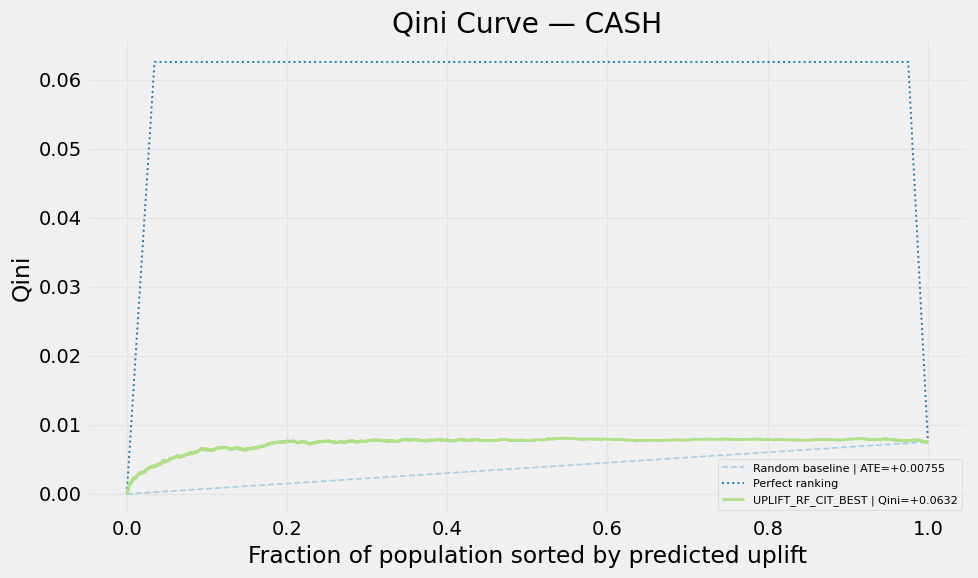

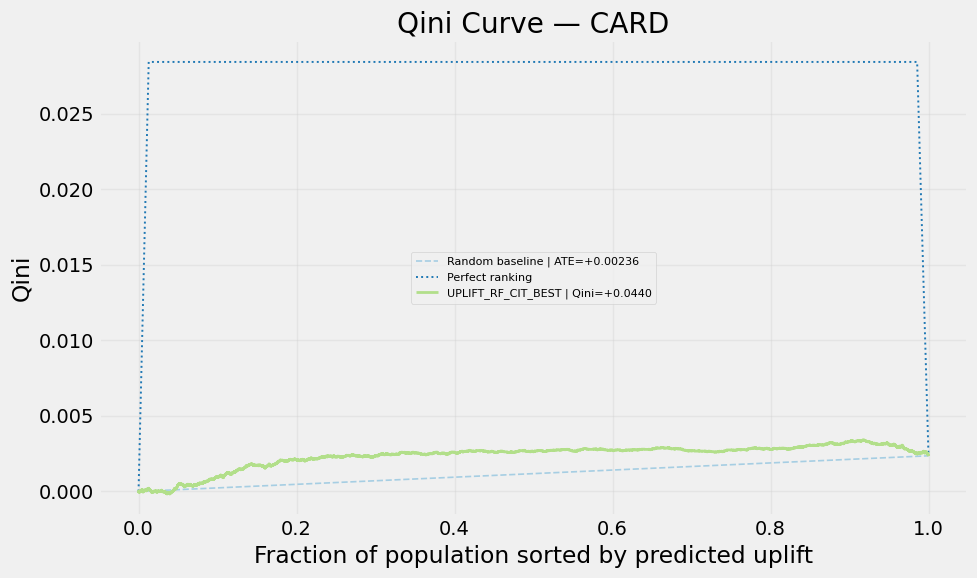

In [11]:
# ============================================================
# 10. QINI CURVES — BEST UPLIFT_RF_CIT
# ============================================================

def plot_qini_compare(target_name, y, w_event, score_dict):
    if not score_dict:
        print(f"No scores for {target_name}")
        return

    plt.figure(figsize=(10, 6))
    xp, qp = qini_curve(y, w_event, oracle_score(y, w_event))
    ate = qp[-1]
    plt.plot([0, 1], [0, ate], "--", linewidth=1.2, label=f"Random baseline | ATE={ate:+.5f}")
    plt.plot(xp, qp, ":", linewidth=1.4, label="Perfect ranking")

    for model_name, score in score_dict.items():
        x, q = qini_curve(y, w_event, score)
        m = qini_metrics(y, w_event, score)
        plt.plot(x, q, linewidth=2, label=f"{model_name} | Qini={m['qini_norm']:+.4f}")

    plt.title(f"Qini Curve — {target_name.upper()}")
    plt.xlabel("Fraction of population sorted by predicted uplift")
    plt.ylabel("Qini")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_qini_compare("cash", Y_cash, w_cash, scores_oof["cash"])
plot_qini_compare("card", Y_card, w_card, scores_oof["card"])


## 8. Export outputs


In [12]:
# ============================================================
# 11. EXPORT OUTPUTS
# ============================================================

def _safe_run_name(text, max_len=80):
    text = "baseline_all_features" if text is None else str(text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", text)
    return text[:max_len].strip("_") or "run"


BASE_OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
if not FEATURE_DROP_BASE_COLS:
    RUN_TAG = "uplift_rf_cit_random_search_baseline_all_features"
else:
    id_part = "ids_" + "-".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)
    name_part = _safe_run_name("__".join(FEATURE_DROP_BASE_COLS), max_len=100)
    RUN_TAG = f"uplift_rf_cit_random_search_drop_{id_part}_{name_part}"

OUTPUT_DIR = BASE_OUTPUT_DIR / RUN_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR)

summary_path = OUTPUT_DIR / "qini_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

random_search_path = OUTPUT_DIR / "uplift_rf_cit_random_search_results.csv"
summary.to_csv(random_search_path, index=False)
print("Saved:", random_search_path)

fold_path = OUTPUT_DIR / "fold_qini_logs.csv"
fold_qini_logs.to_csv(fold_path, index=False)
print("Saved:", fold_path)

fold_mean_path = OUTPUT_DIR / "fold_mean_qini_by_model.csv"
fold_mean_qini_by_model.to_csv(fold_mean_path, index=False)
print("Saved:", fold_mean_path)

run_log_df = pd.DataFrame(run_log)
run_log_path = OUTPUT_DIR / "run_log.csv"
run_log_df.to_csv(run_log_path, index=False)
print("Saved:", run_log_path)

best_config_path = OUTPUT_DIR / "uplift_rf_cit_best_config_A.json"
with open(best_config_path, "w", encoding="utf-8") as f:
    json.dump(to_builtin(A), f, ensure_ascii=False, indent=2)
print("Saved:", best_config_path)

train_id = make_id_series(feat, id_col=ID_COL)

oof_out = pd.DataFrame()
oof_out[train_id.name] = train_id.values
oof_out["treatment_cash"] = W
oof_out["cash_sign_30d"] = Y_cash
oof_out["card_sign_30d"] = Y_card
oof_out["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
oof_out["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
oof_out["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
for name, score in scores_oof["cash"].items():
    oof_out[f"cash_{name}"] = score
for name, score in scores_oof["card"].items():
    oof_out[f"card_{name}"] = score

oof_path = OUTPUT_DIR / "oof_model_scores.csv"
oof_out.to_csv(oof_path, index=False)
print("Saved:", oof_path)

if best_model is not None:
    final_train = pd.DataFrame()
    final_train[train_id.name] = train_id.values
    final_train["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
    final_train["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
    final_train["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
    final_train["best_model"] = best_model
    final_train["best_config_id"] = A["best_config_id"]
    final_train["uplift_cash_score"] = scores_oof["cash"][best_model]
    final_train["uplift_card_score"] = scores_oof["card"][best_model]
    final_train["cash_vs_card_score"] = final_train["uplift_cash_score"] - final_train["uplift_card_score"]
    final_train["recommended_product"] = np.where(final_train["cash_vs_card_score"] >= 0, "Cash", "Card")

    final_train_path = OUTPUT_DIR / "final_scores_train.csv"
    final_train.to_csv(final_train_path, index=False)
    print("Saved:", final_train_path)

    if X_test is not None and best_model in scores_test["cash"] and best_model in scores_test["card"]:
        submission = pd.DataFrame()
        submission[test_id.name] = test_id.values
        submission["best_model"] = best_model
        submission["best_config_id"] = A["best_config_id"]
        submission["uplift_cash_score"] = scores_test["cash"][best_model]
        submission["uplift_card_score"] = scores_test["card"][best_model]
        submission["cash_vs_card_score"] = submission["uplift_cash_score"] - submission["uplift_card_score"]
        submission["recommended_product"] = np.where(submission["cash_vs_card_score"] >= 0, "Cash", "Card")

        submission_path = OUTPUT_DIR / "submission.csv"
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path)
    else:
        print("Skip submission: không có X_test hoặc best_model không có test score.")
else:
    print("Skip final score export: không có best_model.")

feature_drop_result = {
    "COL_IDX_config": str(COL_IDX),
    "feature_drop_col_idx": FEATURE_DROP_COL_IDX,
    "feature_drop_base_col": FEATURE_DROP_BASE_COL,
    "n_feature_drop_base_cols": len(FEATURE_DROP_BASE_COLS),
    "feature_drop_base_cols": "|".join(FEATURE_DROP_BASE_COLS),
    "n_dropped_train_cols": len(drop_cols_in_feat),
    "dropped_train_cols": "|".join(drop_cols_in_feat),
    "n_features_after_drop": len(FEAT_COLS),
    "best_model": best_model,
    "best_config_id": A["best_config_id"],
    "random_search_n_iter": A["random_search_n_iter"],
    "best_params_json": json.dumps(to_builtin(A["best_params"]), ensure_ascii=False, sort_keys=True),
    "best_causalml_kwargs_json": json.dumps(to_builtin(A["best_causalml_kwargs"]), ensure_ascii=False, sort_keys=True),
    "best_Qini_coefficient_cash": A["Qini_coefficient_cash"],
    "best_Qini_coefficient_card": A["Qini_coefficient_card"],
    "best_Qini_coefficient_total": A["Qini_coefficient_total"],
}

feature_drop_result_path = OUTPUT_DIR / "feature_drop_result.csv"
pd.DataFrame([feature_drop_result]).to_csv(feature_drop_result_path, index=False)
print("Saved:", feature_drop_result_path)

print("\n" + "=" * 120, flush=True)
print("FINAL BEST CONFIGURATION A — COPY THIS FROM KAGGLE LOGS", flush=True)
print("A = " + pprint.pformat(A, sort_dicts=False, width=160), flush=True)
print("=" * 120, flush=True)


Output dir: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/qini_summary.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/uplift_rf_cit_random_search_results.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/fold_qini_logs.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/fold_mean_qini_by_model.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/run_log.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/uplift_rf_cit_best_config_A.json
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/oof_model_scores.csv
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/final_scores_train.csv
Skip submission: không có X_test hoặc best_model không có test score.
Saved: /kaggle/working/uplift_rf_cit_random_search_baseline_all_features/fe

## 9. Cách đọc kết quả

Các file quan trọng sau khi chạy:

- `uplift_rf_cit_random_search_results.csv`: toàn bộ kết quả random search của **UPLIFT_RF_CIT**.
- `qini_summary.csv`: giống random search results, đã sort theo `Qini_coefficient_total`.
- `fold_qini_logs.csv`: Qini từng fold cho từng configuration.
- `fold_mean_qini_by_model.csv`: Qini trung bình 5 fold theo từng configuration.
- `uplift_rf_cit_best_config_A.json`: configuration tốt nhất, cùng nội dung với biến **A** in trong Kaggle Logs.
- `feature_drop_result.csv`: file gọn nhất để so sánh các lần drop feature.
- `final_scores_train.csv`: score uplift Cash/Card của best model và khuyến nghị Cash/Card trên train.
- `submission.csv`: chỉ tạo nếu notebook tìm thấy test feature đã clean/one-hot tương thích với `df_feature.csv`.

Trong Kaggle Logs, tìm đoạn:

```python
BEST CONFIGURATION FOR REPRODUCTION — COPY THIS FROM KAGGLE LOGS
A = {...}
```

Copy nguyên biến **A** để tái tạo lại model tốt nhất.
